# CAS ADS M3 Project - Predicting Members Exit Intentions

**Author:** Cornel Gübeli
**Date:** 2026-10-29

## Initial Remark
Please note that this notebook is my second attempt to coding with real data and is heavily influenced by my good friend GPT 6. I'm very happy about any feedback and eager to learn more. A lot of code seem to be more complicated than they could be...

## Objective
This notebook cleans, explores and analyses data on a survey conducted with 25 Swiss voluntarly football clubs as part of the national initiative "SFV Quality Club". Data was collected between the 01.01.2024 and 31.12.2024. The goal of the initiative is to support and develop voluntary sports clubs in order to harness their societal potential. The survey was sent out by the club to it's members and, in case of minors, their parents. 

## Research Question
RQ: How can we precict club members intention to leave the club?

## Resources
SFV Quality Club program details: https://org.football.ch/vereinsentwicklung/quality-club.aspx

# Load Packages


In [198]:
# import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl
import sklearn

# Data Cleaning
This part of the notebook I would never show in a public repository, as it gives others an insight into the pseudomization process

In [199]:
# import raw data from xlsx file
RAWDATA = pd.read_excel(r"C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey\Gesamtdaten 2024 - SFV Quality Club.xlsx", engine='openpyxl')
df = RAWDATA.copy()  # Create a copy of the raw data for processing



In [200]:
#assign labels according to codebook

# 1. Load the first two rows of your completed codebook
CODEBOOK = pd.read_excel(
    "C:\\Users\\guebeli.SPW\\Documents\\Data_CASADS_Projects\\M3_Data_SFV_Survey\\Full_Codebook_SFV_Quality_Club_Data.xlsx",
    sheet_name="Tabelle1",
    header=None,
    nrows=2
)

# 3. Extract original headers and new variable names
# Skip column A because it contains descriptions
old_names = CODEBOOK.iloc[0, 1:].tolist()
new_names = CODEBOOK.iloc[1, 1:].tolist()

# 4. Create mapping dictionary
mapping = dict(zip(old_names, new_names))

# 5. Check for columns not found in the codebook
unmatched = [
    col for col in df.columns
    if col not in mapping
]

if unmatched:
    print("WARNING: The following columns were not found:")
    for col in unmatched:
        print(col)

# 6. Rename columns
df = df.rename(columns=mapping)

# 7. Check for duplicate variable names
if df.columns.duplicated().any():
    raise ValueError("Duplicate variable names detected!")

# 8. Display results
print("\nCOLUMN RENAMING RESULTS")
print("Total columns:", len(df.columns))
print("Columns renamed:", len(df.columns) - len(unmatched))
print("Unmatched columns:", len(unmatched))

# 9. Show dataframe info and first few rows
df.head()



COLUMN RENAMING RESULTS
Total columns: 271
Columns renamed: 271
Unmatched columns: 0


,id,date_sent,last_page,language,random_n,ip,club,tot_sat,strat_part_sat,strat_imp,...,vol_willing_other_text,vol_contact_consent,vol_contact_details,birth_year,education_level,employment_extent,household_income_cat,gender,club_positive_text,club_improvements_text
0,6,NaN,NaN,de,1411403760,104.28.135.84,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7,1980-01-01 00:00:00,18.0,de,979837807,188.61.117.237,FC Raron,zufrieden,weder noch,wichtig,...,NaN,NaN,NaN,1981.0,"Hochschulen (Bachelor FH/PH/Uni, Master FH/PH/...",Ich gehe keiner Beschäftigung nach (z.B. in Re...,NaN,Weiblich,NaN,NaN
2,8,1980-01-01 00:00:00,18.0,de,1156841452,178.197.194.117,FC Raron,weder noch,weder noch,sehr wichtig,...,NaN,NaN,NaN,1982.0,"Höhere Berufsbildung (Berufsprüfung, Höhere Fa...",Vollzeit (90-100%),115’001-150'000,Männlich,NaN,NaN
3,9,1980-01-01 00:00:00,18.0,de,1617143157,146.136.160.37,FC Münsterlingen,sehr zufrieden,zufrieden,sehr wichtig,...,NaN,NaN,NaN,1998.0,"Hochschulen (Bachelor FH/PH/Uni, Master FH/PH/...",Mehr als Vollzeit,Unter 50'000,Männlich,NaN,NaN
4,10,1980-01-01 00:00:00,18.0,de,1708915218,83.76.205.189,FC Raron,sehr zufrieden,zufrieden,sehr wichtig,...,NaN,NaN,NaN,1979.0,"Höhere Berufsbildung (Berufsprüfung, Höhere Fa...",Vollzeit (90-100%),80’001-95'000,Männlich,Tradition und Förderung der Junioren,Mithilfe der Mitglieder


In [201]:
# remove private data (IP and Phone Number)
df = df.drop(columns=[
    "ip",
    "vol_contact_details"
])

In [202]:
# pseudonymization of clubs
# 1. Enter the real club names
# Replace each placeholder with the exact name from LimeSurvey

club_names = [
    "BSC Old Boys",
    "CS Italien GE",
    "FC Affoltern am Albis",
    "FC Boudry",
    "FC Embrach",
    "FC Ems",
    "FC Gerzensee",
    "FC Länggasse",
    "FC Münsterlingen",
    "FC Niederlenz",
    "FC Nordstern Basel",
    "FC Raron",
    "FC Rupperswil",
    "FC Seefeld ZH",
    "FC Seuzach",
    "FC Spiez",
    "FC Sursee",
    "FC Tavannes/Tramelan",
    "FC Utzenstorf",
    "FC Venoge",
    "FC Villars-sur-Glâne",
    "FC Wil 1900",
    "Pully Football",
    "SC Emmen",
    "Urania Genève Sport"
]

# 2. Create mapping automatically
club_mapping = {
    name: f"Club {chr(65 + i)}"
    for i, name in enumerate(club_names)
}

# 3. Check for unrecognized clubs
unknown = set(df["club"].dropna()) - set(club_mapping)

if unknown:
    raise ValueError(f"Unknown club names: {sorted(unknown)}")

# 4. Save mapping in a separate Excel file
mapping_df = pd.DataFrame(
    club_mapping.items(),
    columns=["original_club_name", "pseudonym"]
)

mapping_df.to_excel(r"C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey\SFV_2024_club_mapping_confidential.xlsx",
    index=False
)

# 5. Replace real club names with pseudonyms
df["club"] = df["club"].replace(club_mapping)

# 6. Save the pseudonymized dataset to a new Excel file
df.to_excel(r"C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey\SFV_2024_pseudonymized_survey.xlsx", index=False)

df.head()

,id,date_sent,last_page,language,random_n,club,tot_sat,strat_part_sat,strat_imp,vision_sat,...,vol_willing_medical,vol_willing_other_text,vol_contact_consent,birth_year,education_level,employment_extent,household_income_cat,gender,club_positive_text,club_improvements_text
0,6,NaN,NaN,de,1411403760,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7,1980-01-01 00:00:00,18.0,de,979837807,Club L,zufrieden,weder noch,wichtig,unzufrieden,...,NaN,NaN,NaN,1981.0,"Hochschulen (Bachelor FH/PH/Uni, Master FH/PH/...",Ich gehe keiner Beschäftigung nach (z.B. in Re...,NaN,Weiblich,NaN,NaN
2,8,1980-01-01 00:00:00,18.0,de,1156841452,Club L,weder noch,weder noch,sehr wichtig,unzufrieden,...,NaN,NaN,NaN,1982.0,"Höhere Berufsbildung (Berufsprüfung, Höhere Fa...",Vollzeit (90-100%),115’001-150'000,Männlich,NaN,NaN
3,9,1980-01-01 00:00:00,18.0,de,1617143157,Club I,sehr zufrieden,zufrieden,sehr wichtig,sehr zufrieden,...,NaN,NaN,NaN,1998.0,"Hochschulen (Bachelor FH/PH/Uni, Master FH/PH/...",Mehr als Vollzeit,Unter 50'000,Männlich,NaN,NaN
4,10,1980-01-01 00:00:00,18.0,de,1708915218,Club L,sehr zufrieden,zufrieden,sehr wichtig,zufrieden,...,NaN,NaN,NaN,1979.0,"Höhere Berufsbildung (Berufsprüfung, Höhere Fa...",Vollzeit (90-100%),80’001-95'000,Männlich,Tradition und Förderung der Junioren,Mithilfe der Mitglieder


In [203]:
"""Recode a pseudonymized SFV LimeSurvey export using the horizontal codebook.

You may run this as a .py file or paste the whole file into one Jupyter cell.
The raw dataset and codebook are never overwritten.

Codebook sheet Tabelle1:
    row 2 = renamed variable names
    row 3 = response types / descriptions
    column A = row descriptions (ignored)
"""

from pathlib import Path
import re
import pandas as pd


# ---------------------------------------------------------------------------
# 1. FILE LOCATIONS 
# ---------------------------------------------------------------------------
DATA_DIR = Path(
    r"C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey"
)

INPUT_FILE = DATA_DIR / "SFV_2024_pseudonymized_survey.xlsx"
CODEBOOK_FILE = DATA_DIR / "Full_Codebook_SFV_Quality_Club_Data.xlsx"
OUTPUT_FILE = DATA_DIR / "SFV_2024_recoded_cleaned.xlsx"
REPORT_FILE = DATA_DIR / "SFV_2024_recoding_report.xlsx"
UNKNOWN_FILE = DATA_DIR / "SFV_2024_recoding_unknown_values.csv"

# Used if date_sent is missing (or missing for individual respondents).
# Leave None if every respondent has a usable date_sent, or set e.g. 2024.
SURVEY_YEAR = None


# ---------------------------------------------------------------------------
# 2. EXACT RESPONSE LABELS IN LIMESURVEY
# ---------------------------------------------------------------------------
SATISFACTION = {
    "sehr unzufrieden": 1,
    "unzufrieden": 2,
    "weder noch": 3,
    "zufrieden": 4,
    "sehr zufrieden": 5,
}

IMPORTANCE = {
    "überhaupt nicht wichtig": 1,
    "nicht wichtig": 2,
    "weder noch": 3,
    "wichtig": 4,
    "sehr wichtig": 5,
}

AGREEMENT = {
    "trifft nicht zu": 1,
    "trifft eher nicht zu": 2,
    "weder noch": 3,
    "trifft eher zu": 4,
    "trifft voll zu": 5,
    "weiss nicht": pd.NA,
}

YES_NO = {"Nein": 0, "Ja": 1, "nein": 0, "ja": 1}
EXIT_THREE_LEVELS = {"Nein": 0, "Ja, manchmal": 1, "Ja, oft": 2}


FOOTBALL_FREQUENCY = {
    "monatlich": 1,
    "zweiwöchentlich": 2,
    "1x pro Woche": 3,
    "2x pro Woche": 4,
    "3x pro Woche": 5,
    "4x pro Woche": 6,
    "5x pro Woche": 7,
    "6x pro Woche": 8,
    "mehr als 6x pro Woche": 9,
}

FOOTBALL_HOURS = {
    "weniger als 1h pro Woche": 1,
    "1-2h pro Woche": 2,
    "2-3h pro Woche": 3,
    "3-4h pro Woche": 4,
    "4-5h pro Woche": 5,
    "5-6h pro Woche": 6,
    "6-7h pro Woche": 7,
    "mehr als 7h pro Woche": 8,
}

VOLUNTEERING_YEARS = {
    "Weniger als 1 Jahr": 1,
    "1-2 Jahre": 2,
    "2-5 Jahre": 3,
    "5-10 Jahre": 4,
    "Über 10 Jahre": 5,
}

VOLUNTEERING_HOURS = {
    "Weniger als 1 Stunde": 1,
    "1-2 Stunden": 2,
    "2-5 Stunden": 3,
    "5-10 Stunden": 4,
    "Über 10 Stunden": 5,
}


# ---------------------------------------------------------------------------
# 3. RECODING RULES
# ---------------------------------------------------------------------------
def allow_existing_numeric_codes(mapping):
    """Accept previously recoded numeric values on repeat runs."""
    extended = mapping.copy()
    for value in mapping.values():
        if isinstance(value, int):
            extended[value] = value
            extended[str(value)] = value
    return extended


def code_for(variable_name, data_type):
    """Return (mapping, description), or (None, description) to preserve a field."""
    t = str(data_type).strip().lower()
    variable = str(variable_name).strip().lower()


    # All free-text fields, including vol_other and child_exit_reason_text.
    if t == "string":
        return None, "Text response (preserved)"

    if variable in {"exit", "child_exit"}:
        return EXIT_THREE_LEVELS, "Three-category exit intention"

    if t.startswith("likert"):
        if '"sehr unzufrieden"' in t:
            return SATISFACTION, "Satisfaction (1-5)"
        if '"überhaupt nicht wichtig"' in t:
            return IMPORTANCE, "Importance (1-5)"
        if '"trifft nicht zu"' in t:
            return AGREEMENT, "Agreement (1-5)"
        raise ValueError(
            f"Unrecognized Likert type in codebook for {variable_name}: {data_type}"
        )

    if t.startswith("binary"):
        return YES_NO, "Binary Yes/No"

    if t.startswith("ordinal"):
        if "monatlich" in t:
            return FOOTBALL_FREQUENCY, "Football frequency (ordered categories)"
        if "weniger als 1h pro woche" in t:
            return FOOTBALL_HOURS, "Football hours (ordered categories)"
        raise ValueError(
            f"Unrecognized ordinal type in codebook for {variable_name}: {data_type}"
        )

    if t.startswith("categorical") or t.startswith("categorial"):
        if "weniger als 1 jahr" in t:
            return VOLUNTEERING_YEARS, "Volunteering years (ordered categories)"
        if "weniger als 1 stunde" in t:
            return VOLUNTEERING_HOURS, "Volunteering hours (ordered categories)"
        if re.search(r'"nein"\s*,\s*"ja"', t):
            return YES_NO, "Binary Yes/No"
        # Other nominal categories are not assigned arbitrary numeric ranks.
        return None, "Nominal categories (preserved)"

    # IDs, dates, existing numeric and other unclassified variables.
    return None, "Preserved (no validated recoding rule)"


# ---------------------------------------------------------------------------
# 4. ADD APPROXIMATE AGE 
# ---------------------------------------------------------------------------
# def add_age_from_birth_year(df):
#     """Age = submission year - birth year (not exact age without birthday)."""
#     if "birth_year" not in df.columns:
#         raise ValueError("Column 'birth_year' is missing from the dataset.")
#     if "age" in df.columns:
#         raise ValueError("Column 'age' already exists; will not overwrite it.")

#     birth_year = pd.to_numeric(df["birth_year"], errors="coerce")
#     bad_birth = df["birth_year"].notna() & birth_year.isna()
#     if bad_birth.any():
#         raise ValueError(f"{int(bad_birth.sum())} birth_year values are not numeric.")
#     if (birth_year.notna() & (birth_year % 1 != 0)).any():
#         raise ValueError("birth_year contains non-integer values.")
#     birth_year = birth_year.astype("Int64")

#     if "date_sent" in df.columns:
#         dates = pd.to_datetime(
#             df["date_sent"], errors="coerce", format="mixed", dayfirst=True
#         )
#         bad_dates = df["date_sent"].notna() & dates.isna()
#         if bad_dates.any():
#             raise ValueError(f"{int(bad_dates.sum())} date_sent values cannot be parsed.")
#         reference_year = dates.dt.year.astype("Int64")
#     else:
#         reference_year = pd.Series(pd.NA, index=df.index, dtype="Int64")

#     if SURVEY_YEAR is not None:
#         reference_year = reference_year.fillna(int(SURVEY_YEAR))
#     if reference_year.isna().all():
#         raise ValueError("No survey year available. Set SURVEY_YEAR above.")

#     age = (reference_year - birth_year).astype("Int64")
#     if (age.notna() & ((age < 0) | (age > 110))).any():
#         raise ValueError("Implausible ages detected: verify birth_year and date_sent.")
#     df["age"] = age
#     return df


# ---------------------------------------------------------------------------
# 5. EXECUTE RECODING AND SAVE REPORTS
# ---------------------------------------------------------------------------
def main():
    if INPUT_FILE.resolve() == OUTPUT_FILE.resolve():
        raise ValueError("Input and output must have different filenames.")

    df = pd.read_excel(INPUT_FILE)
    codebook = pd.read_excel(
        CODEBOOK_FILE, sheet_name="Tabelle1", header=None, nrows=3
    )
    names = codebook.iloc[1, 1:].tolist()
    types = codebook.iloc[2, 1:].tolist()

    if len(names) != len(set(names)):
        raise ValueError("Duplicate variable names in codebook row 2.")
    specs = dict(zip(names, types))

    matched = [c for c in df.columns if c in specs]
    print(f"Input columns: {df.shape[1]}")
    print(f"Columns matched to codebook: {len(matched)}")
    if not matched:
        raise ValueError(
            "No dataset columns match codebook variable names. "
            "Check that the original question headers were renamed first, "
            "and that CODEBOOK_FILE is the correct workbook."
        )

    audit = []
    unknown_rows = []
    recoded_columns = 0

    for col in df.columns:
        if col not in specs:
            audit.append({"variable": col, "action": "Not in codebook; preserved"})
            continue

        mapping, action = code_for(col, specs[col])
        series = df[col]
        if mapping is None:
            audit.append({
                "variable": col,
                "type_in_codebook": specs[col],
                "action": action,
                "valid_n": int(series.notna().sum()),
                "missing_n": int(series.isna().sum()),
            })
            continue

        mapping = allow_existing_numeric_codes(mapping)
        unknown = series.notna() & ~series.isin(mapping.keys())
        for value, count in series.loc[unknown].value_counts().items():
            unknown_rows.append({
                "variable": col,
                "unexpected_value": value,
                "frequency": int(count),
            })

        audit.append({
            "variable": col,
            "type_in_codebook": specs[col],
            "action": action,
            "valid_n": int(series.notna().sum()),
            "missing_n": int(series.isna().sum()),
            "unknown_n": int(unknown.sum()),
        })

        if not unknown.any():
            df[col] = series.map(mapping).astype("Int64")
            recoded_columns += 1

    if unknown_rows:
        pd.DataFrame(unknown_rows).to_csv(
            UNKNOWN_FILE, index=False, encoding="utf-8-sig"
        )
        pd.DataFrame(audit).to_excel(REPORT_FILE, index=False)
        print(f"Unknown labels found: {len(unknown_rows)} variable/value pairs.")
        print(f"Inspect: {UNKNOWN_FILE}")
        raise ValueError(
            "Recoding halted: unexpected response labels remain. "
            "No new recoded dataset has been saved."
        )

    if recoded_columns == 0:
        raise ValueError(
            "No variables recoded: inspect codebook types and column names."
        )

    # Keep original three-category exit variables AND binary versions.
    for col in ("exit", "child_exit"):
        if col in df.columns:
            df[f"{col}_binary"] = df[col].map({0: 0, 1: 1, 2: 1}).astype("Int64")

    # df = add_age_from_birth_year(df)
    # audit.append({
    #     "variable": "age",
    #     "type_in_codebook": "Derived variable",
    #     "action": "Submission year minus birth year (approximate)",
    #     "valid_n": int(df["age"].notna().sum()),
    #     "missing_n": int(df["age"].isna().sum()),
    #})

    df.to_excel(OUTPUT_FILE, index=False)
    pd.DataFrame(audit).to_excel(REPORT_FILE, index=False)
    print(f"Recoding complete: {recoded_columns} variables recoded.")
    print(f"Recoded dataset: {OUTPUT_FILE}")
    print(f"Audit report: {REPORT_FILE}")
    print("Text, IDs, club pseudonyms and other nominal variables were preserved.")


if __name__ == "__main__":
    main()

Input columns: 269
Columns matched to codebook: 269
Recoding complete: 246 variables recoded.
Recoded dataset: C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey\SFV_2024_recoded_cleaned.xlsx
Audit report: C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey\SFV_2024_recoding_report.xlsx
Text, IDs, club pseudonyms and other nominal variables were preserved.


In [204]:
# create missing values report
missing_report = pd.DataFrame({
    "missing_n": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100
})

missing_report = missing_report.sort_values(
    by="missing_pct",
    ascending=False
)

print("\nMISSING VALUES REPORT")
print(missing_report.round(2))

# Save missing-values report
missing_report.to_excel(
    "SFV_2024_missing_values_report.xlsx"
)



MISSING VALUES REPORT
                        missing_n  missing_pct
vol_willing_other_text       6602        99.85
vol_medical_years_cat        6588        99.64
vol_medical_hours_cat        6586        99.61
vol_recruitment_other        6581        99.53
vol_referee_hours_cat        6560        99.21
...                           ...          ...
club                          771        11.66
last_page                     630         9.53
random_n                        0         0.00
language                        0         0.00
id                              0         0.00

[269 rows x 2 columns]


In [205]:
# create missing values report
missing_report = pd.DataFrame({
    "missing_n": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100
})

missing_report = missing_report.sort_values(
    by="missing_pct",
    ascending=False
)

print("\nMISSING VALUES REPORT")
print(missing_report.round(2))

# Save missing-values report
missing_report.to_excel(
    "SFV_2024_missing_values_report.xlsx"
)



MISSING VALUES REPORT
                        missing_n  missing_pct
vol_willing_other_text       6602        99.85
vol_medical_years_cat        6588        99.64
vol_medical_hours_cat        6586        99.61
vol_recruitment_other        6581        99.53
vol_referee_hours_cat        6560        99.21
...                           ...          ...
club                          771        11.66
last_page                     630         9.53
random_n                        0         0.00
language                        0         0.00
id                              0         0.00

[269 rows x 2 columns]


# Selecting relevant data for analysis

The following section selects the relevant data for machine learning models. 

In [206]:
# load data
df = pd.read_excel(r"C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey\SFV_2024_recoded_cleaned.xlsx")


In [207]:
# select relevant variables for machine learning analyis

# 1. Select relevant variables
columns = [
   "id",
   "club",
   "exit_binary",
   "tot_sat",
   "pride",
   "wellbeing",
   "lead_sat",
  
]

# 2. Create a reduced DataFrame
df = df[columns].copy()

# 3. Display results
print(df.head())
print("Number of respondents:", len(df))
print("Number of variables:", len(df.columns))

   id    club  exit_binary  tot_sat  pride  wellbeing  lead_sat
0   6     NaN          NaN      NaN    NaN        NaN       NaN
1   7  Club L          0.0      4.0    3.0        4.0       2.0
2   8  Club L          0.0      3.0    5.0        3.0       3.0
3   9  Club I          0.0      5.0    5.0        5.0       4.0
4  10  Club L          0.0      5.0    5.0        5.0       5.0
Number of respondents: 6612
Number of variables: 7


In [208]:
# Select variables
variables_ml = [
    "exit_binary",
    "tot_sat",
    "pride",
    "wellbeing",
    "lead_sat",
]

# Create missing values report
missing_report_ml = pd.DataFrame({
    "missing_n": df[variables_ml].isna().sum(),
    "missing_pct": df[variables_ml].isna().mean() * 100
})

# Sort by percentage of missing values
missing_report_ml = missing_report_ml.sort_values(
    by="missing_pct",
    ascending=False
)

print("\nMISSING VALUES REPORT")
print(missing_report_ml.round(2))


MISSING VALUES REPORT
             missing_n  missing_pct
pride             4102        62.04
wellbeing         4073        61.60
exit_binary       3869        58.51
lead_sat          3149        47.63
tot_sat           1238        18.72


# Descriptive Analysis

In [209]:
# create missing values report
missing_report = pd.DataFrame({
    "missing_n": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100
})

missing_report = missing_report.sort_values(
    by="missing_pct",
    ascending=False
)

print("\nMISSING VALUES REPORT")
print(missing_report.round(2))


MISSING VALUES REPORT
             missing_n  missing_pct
pride             4102        62.04
wellbeing         4073        61.60
exit_binary       3869        58.51
lead_sat          3149        47.63
tot_sat           1238        18.72
club               771        11.66
id                   0         0.00


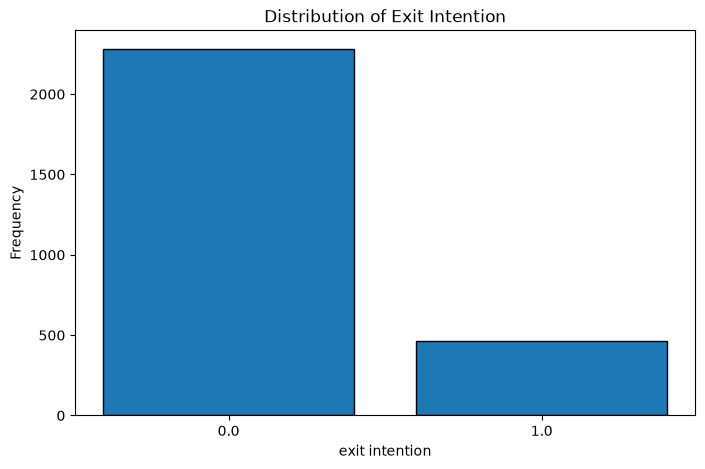

In [210]:
#create a bar plot to visualize the distribution of exit intention

# Count responses for each category
counts = df["exit_binary"].value_counts().sort_index()

# Create bar plot
plt.figure(figsize=(8, 5))
plt.bar(counts.index.astype(str), counts.values, edgecolor="black")

plt.xlabel("exit intention")
plt.ylabel("Frequency")
plt.title("Distribution of Exit Intention")

plt.show()

# Comparing Machine Learning Models

# Logistic regression
I'm starting with the simplest model, an univariate logistic regression using tot_sat as a regressor and exit_binary as a regressand. 


In [211]:
"""Univariate Logistic Regression Model to Predict Exit Intention"""

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

# 1. Prepare data
data_logit = df[["tot_sat", "exit_binary"]].copy()

data_logit = data_logit.apply(
    pd.to_numeric, errors="coerce"
).dropna()

# 2. Define predictor (X) and outcome (y)
X = data_logit[["tot_sat"]]
y = data_logit["exit_binary"].astype(int)

# 3. Train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 4. Fit logistic regression
model_logit = LogisticRegression(
    C=np.inf,
    solver="lbfgs",
    max_iter=1000
)

model_logit.fit(X_train, y_train)

# 5. Training and test scores (accuracy)
train_score = model_logit.score(X_train, y_train)
test_score = model_logit.score(X_test, y_test)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print(f"Training score: {train_score:.3f}")
print(f"Test score:     {test_score:.3f}")

# 6. Train and test predictions
y_proba_train = model_logit.predict_proba(X_train)[:, 1]
y_proba_test = model_logit.predict_proba(X_test)[:, 1]

# Accuracy
accuracy_train = accuracy_score(y_train, y_pred_train)
accuracy_test = accuracy_score(y_test, y_pred_test)

# F1 Score
f1_train = f1_score(y_train, y_pred_train, zero_division=0)
f1_test = f1_score(y_test, y_pred_test, zero_division=0)

# 7. Additional performance metrics
print("\nMODEL PERFORMANCE")
print(f"Training ROC-AUC: {roc_auc_score(y_train, y_proba_train):.3f}")
print(f"Test ROC-AUC:     {roc_auc_score(y_test, y_proba_test):.3f}")
print(f"Training Brier:   {brier_score_loss(y_train, y_proba_train):.3f}")
print(f"Test Brier:       {brier_score_loss(y_test, y_proba_test):.3f}")
print(f"Training Accuracy: {accuracy_train:.3f}")
print(f"Test Accuracy:     {accuracy_test:.3f}")
print(f"Training F1 Score: {f1_train:.3f}")
print(f"Test F1 Score:     {f1_test:.3f}")

# 8. Coefficients and odds ratio
intercept = model_logit.intercept_[0]
coefficient = model_logit.coef_[0][0]

print("\nMODEL COEFFICIENTS")
print(f"Intercept: {intercept:.4f}")
print(f"Coefficient (tot_sat): {coefficient:.4f}")
print(f"Odds Ratio (tot_sat): {np.exp(coefficient):.4f}")


LOGISTIC REGRESSION RESULTS
---------------------------
Training score: 0.833
Test score:     0.832

MODEL PERFORMANCE
Training ROC-AUC: 0.685
Test ROC-AUC:     0.693
Training Brier:   0.135
Test Brier:       0.135
Training Accuracy: 0.861
Test Accuracy:     0.849
Training F1 Score: 0.414
Test F1 Score:     0.388

MODEL COEFFICIENTS
Intercept: -0.0418
Coefficient (tot_sat): -0.4041
Odds Ratio (tot_sat): 0.6676


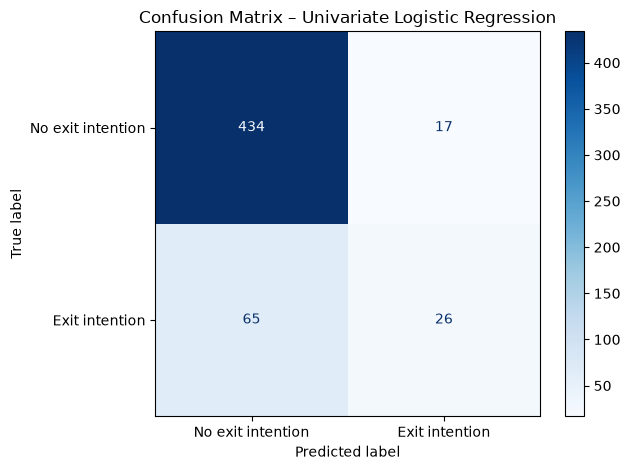

In [212]:

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_test, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No exit intention", "Exit intention"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – Univariate Logistic Regression")
plt.tight_layout()
plt.show()

Now I add more regressors in order to hopefully improve my model.

In [213]:
"""Multivariate Logistic Regression Model to Predict Exit Intention"""

from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.metrics import accuracy_score, f1_score


# 1. Define predictors
predictors = [
    "pride",
    "wellbeing",
    "lead_sat",
    "tot_sat"
]

numeric_predictors = [
    "pride",
    "wellbeing",
    "lead_sat",
    "tot_sat"
]

# 2. Reuse the previous train/test split
X_train_multi = df.loc[X_train.index, predictors].copy()
X_test_multi = df.loc[X_test.index, predictors].copy()

# Ensure numeric predictors are numeric
for col in numeric_predictors:
    X_train_multi[col] = pd.to_numeric(
        X_train_multi[col], errors="coerce"
    )
    X_test_multi[col] = pd.to_numeric(
        X_test_multi[col], errors="coerce"
    )


# 3. Preprocessing
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"),
     numeric_predictors),
])

# 4. Define logistic regression
model_logit_multi = Pipeline([
    ("preprocessor", preprocessor),
    ("logit", LogisticRegression(
        C=np.inf,
        solver="lbfgs",
        max_iter=1000
    ))
])

# 5. Fit model on training data
model_logit_multi.fit(X_train_multi, y_train)

# 6. Training and test scores (accuracy)
train_score = model_logit_multi.score(X_train_multi, y_train)
test_score = model_logit_multi.score(X_test_multi, y_test)

print("MULTIVARIABLE LOGISTIC REGRESSION RESULTS")
print("-----------------------------------------")
print(f"Training score: {train_score:.3f}")
print(f"Test score:     {test_score:.3f}")

# 7. Predicted probabilities
y_proba_train = model_logit_multi.predict_proba(
    X_train_multi
)[:, 1]

y_proba_test = model_logit_multi.predict_proba(
    X_test_multi
)[:, 1]

# 8. Additional performance metrics
print("\nMODEL PERFORMANCE")
print(f"Training ROC-AUC: {roc_auc_score(y_train, y_proba_train):.3f}")
print(f"Test ROC-AUC:     {roc_auc_score(y_test, y_proba_test):.3f}")
print(f"Training Brier:   {brier_score_loss(y_train, y_proba_train):.3f}")
print(f"Test Brier:       {brier_score_loss(y_test, y_proba_test):.3f}")

# 9. Coefficients and odds ratios
feature_names = model_logit_multi.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = model_logit_multi.named_steps[
    "logit"
].coef_[0]

results_multi = pd.DataFrame({
    "Variable": feature_names,
    "Coefficient": coefficients,
    "Odds Ratio": np.exp(coefficients)
})


# Predictions
y_pred_train = model_logit_multi.predict(X_train_multi)
y_pred_test = model_logit_multi.predict(X_test_multi)

# Accuracy
accuracy_train = accuracy_score(y_train, y_pred_train)
accuracy_test = accuracy_score(y_test, y_pred_test)

# F1 Score
f1_train = f1_score(y_train, y_pred_train)
f1_test = f1_score(y_test, y_pred_test)

# Display results
print("MULTIVARIABLE LOGISTIC REGRESSION")
print("--------------------------------")
print(f"Training Accuracy: {accuracy_train:.3f}")
print(f"Test Accuracy:     {accuracy_test:.3f}")
print(f"Training F1 Score: {f1_train:.3f}")
print(f"Test F1 Score:     {f1_test:.3f}")

print("\nMODEL COEFFICIENTS AND ODDS RATIOS")
display(results_multi.round(3))

MULTIVARIABLE LOGISTIC REGRESSION RESULTS
-----------------------------------------
Training score: 0.854
Test score:     0.852

MODEL PERFORMANCE
Training ROC-AUC: 0.775
Test ROC-AUC:     0.784
Training Brier:   0.112
Test Brier:       0.110
MULTIVARIABLE LOGISTIC REGRESSION
--------------------------------
Training Accuracy: 0.854
Test Accuracy:     0.852
Training F1 Score: 0.346
Test F1 Score:     0.355

MODEL COEFFICIENTS AND ODDS RATIOS


,Variable,Coefficient,Odds Ratio
0,numeric__pride,-0.120,0.887
1,numeric__wellbeing,-0.821,0.440
2,numeric__lead_sat,-0.465,0.628
3,numeric__tot_sat,-0.189,0.828


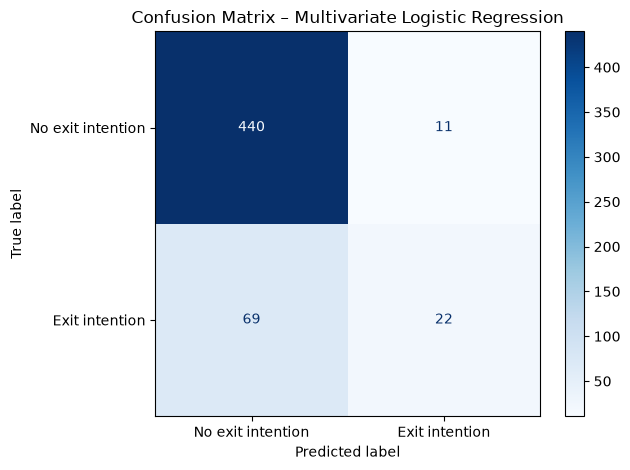

In [214]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred_test, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No exit intention", "Exit intention"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – Multivariate Logistic Regression")
plt.tight_layout()
plt.show()

# Decision Tree model
Next I am running a decision tree model.

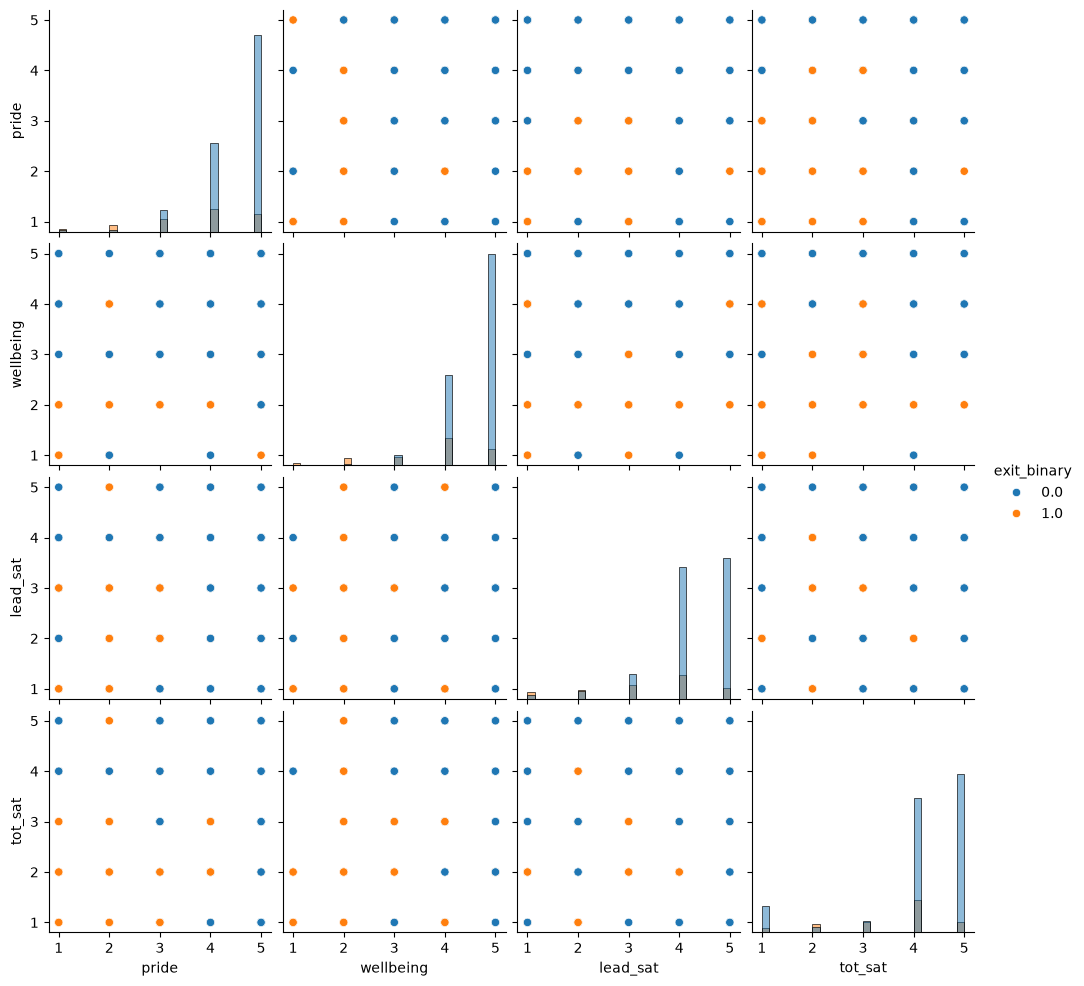

In [215]:
import seaborn as sns
sns.pairplot(df[numeric_predictors + ["exit_binary"]], hue="exit_binary", diag_kind="hist")

DECISION TREE CLASSIFIER
------------------------
Training score: 0.861
Test score:     0.849
MODEL PERFORMANCE
------------------------
Training ROC-AUC: 0.815
Test ROC-AUC:     0.794
Training Brier:   0.104
Test Brier:       0.112
Training Accuracy: 0.861
Test Accuracy:     0.849
Training F1 Score: 0.414
Test F1 Score:     0.388

MODEL PERFORMANCE


,Metric,Training,Test,Gap
0,Accuracy,0.861,0.849,0.013
1,Precision,0.702,0.605,0.097
2,Recall,0.294,0.286,0.008
3,F1 Score,0.414,0.388,0.026
4,ROC-AUC,0.815,0.794,0.021
5,Average Precision,0.544,0.492,0.053
6,Brier Score,0.104,0.112,-0.009



CLASSIFICATION REPORT (TEST DATA)
              precision    recall  f1-score   support

           0       0.87      0.96      0.91       451
           1       0.60      0.29      0.39        91

    accuracy                           0.85       542
   macro avg       0.74      0.62      0.65       542
weighted avg       0.83      0.85      0.83       542



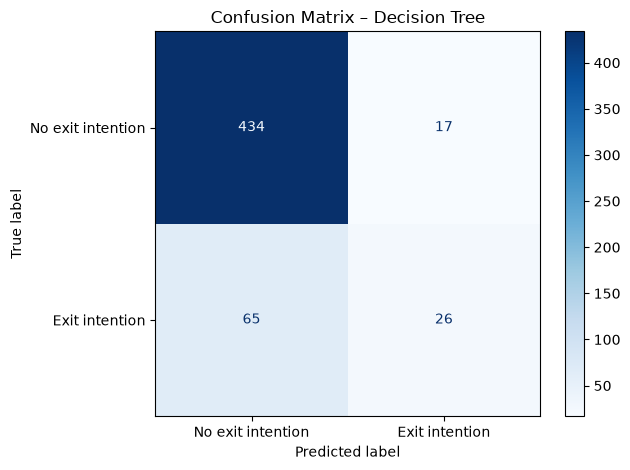

In [216]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Define predictors
numeric_predictors = [
    "pride",
    "wellbeing",
    "lead_sat",
    "tot_sat"
]



# 3. Define decision tree
model_tree = Pipeline([
   # ("preprocessor", preprocessor_tree),
    ("tree", DecisionTreeClassifier(
        criterion="gini",
        max_depth=30,
        min_samples_leaf=10,
        random_state=42
    ))
])

# 4. Fit model on training data
model_tree.fit(X_train_multi, y_train)

# 5. Generate predictions
y_pred_train = model_tree.predict(X_train_multi)
y_pred_test = model_tree.predict(X_test_multi)

# Predicted probabilities
y_proba_train = model_tree.predict_proba(X_train_multi)[:, 1]
y_proba_test = model_tree.predict_proba(X_test_multi)[:, 1]

# 6. Training and test scores (accuracy)
train_score = model_tree.score(X_train_multi, y_train)
test_score = model_tree.score(X_test_multi, y_test)

# 7. Calculate all performance metrics
results_tree = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Average Precision",
        "Brier Score"
    ],
    "Training": [
        accuracy_score(y_train, y_pred_train),
        precision_score(y_train, y_pred_train, zero_division=0),
        recall_score(y_train, y_pred_train, zero_division=0),
        f1_score(y_train, y_pred_train, zero_division=0),
        roc_auc_score(y_train, y_proba_train),
        average_precision_score(y_train, y_proba_train),
        brier_score_loss(y_train, y_proba_train)
    ],
    "Test": [
        accuracy_score(y_test, y_pred_test),
        precision_score(y_test, y_pred_test, zero_division=0),
        recall_score(y_test, y_pred_test, zero_division=0),
        f1_score(y_test, y_pred_test, zero_division=0),
        roc_auc_score(y_test, y_proba_test),
        average_precision_score(y_test, y_proba_test),
        brier_score_loss(y_test, y_proba_test)
    ]
})

# Calculate generalization gap
results_tree["Gap"] = (
    results_tree["Training"] - results_tree["Test"]
)



# Accuracy
accuracy_train = accuracy_score(y_train, y_pred_train)
accuracy_test = accuracy_score(y_test, y_pred_test)

# F1 Score
f1_train = f1_score(y_train, y_pred_train)
f1_test = f1_score(y_test, y_pred_test)

# Display results
print("DECISION TREE CLASSIFIER")
print("------------------------")
print(f"Training score: {train_score:.3f}")
print(f"Test score:     {test_score:.3f}")
print(f"MODEL PERFORMANCE")
print("------------------------")
print(f"Training ROC-AUC: {roc_auc_score(y_train, y_proba_train):.3f}")
print(f"Test ROC-AUC:     {roc_auc_score(y_test, y_proba_test):.3f}")
print(f"Training Brier:   {brier_score_loss(y_train, y_proba_train):.3f}")
print(f"Test Brier:       {brier_score_loss(y_test, y_proba_test):.3f}")
print(f"Training Accuracy: {accuracy_train:.3f}")
print(f"Test Accuracy:     {accuracy_test:.3f}")
print(f"Training F1 Score: {f1_train:.3f}")
print(f"Test F1 Score:     {f1_test:.3f}")

print("\nMODEL PERFORMANCE")
display(results_tree.round(3))

# 8. Classification report
print("\nCLASSIFICATION REPORT (TEST DATA)")
print(classification_report(
    y_test, y_pred_test, zero_division=0
))

# 9. Confusion matrix
cm = confusion_matrix(y_test, y_pred_test, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No exit intention", "Exit intention"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – Decision Tree")
plt.tight_layout()
plt.show()



# Linear SVC
Next, I'm using a linear Support Vector Classifier, as this is the suitable method based on the scikit-learn cheat sheet.

LINEAR SVC CLASSIFIER
---------------------
Training score: 0.853
Test score:     0.854

MODEL PERFORMANCE


,Metric,Training,Test,Gap
0,Accuracy,0.853,0.854,-0.001
1,Precision,0.678,0.688,-0.010
2,Recall,0.227,0.242,-0.015
3,F1 Score,0.340,0.358,-0.017
4,ROC-AUC,0.774,0.784,-0.010
5,Average Precision,0.488,0.514,-0.026
6,Brier Score,0.112,0.110,0.001


LINEAR SVC CLASSIFIER
------------------------
Training score: 0.853
Test score:     0.854
MODEL PERFORMANCE
------------------------
Training ROC-AUC: 0.774
Test ROC-AUC:     0.784
Training Brier:   0.112
Test Brier:       0.110
Training Accuracy: 0.853
Test Accuracy:     0.854
Training F1 Score: 0.340
Test F1 Score:     0.358

CLASSIFICATION REPORT (TEST DATA)
              precision    recall  f1-score   support

           0       0.86      0.98      0.92       451
           1       0.69      0.24      0.36        91

    accuracy                           0.85       542
   macro avg       0.78      0.61      0.64       542
weighted avg       0.83      0.85      0.82       542



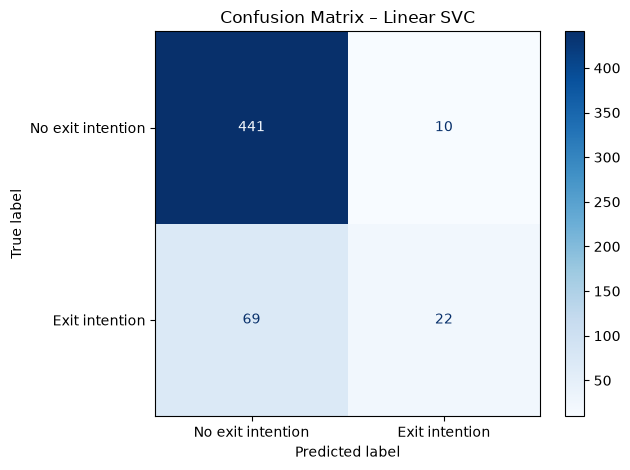

In [220]:
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Use the same train/test data as previous models
X_train_svc = X_train_multi.copy()
X_test_svc = X_test_multi.copy()

# 2. Define predictors
numeric_predictors = [
    "pride",
    "wellbeing",
    "lead_sat",
    "tot_sat"
]

# Ensure numeric predictors have numeric values
for col in numeric_predictors:
    X_train_svc[col] = pd.to_numeric(
        X_train_svc[col], errors="coerce"
    )
    X_test_svc[col] = pd.to_numeric(
        X_test_svc[col], errors="coerce"
    )


# 3. Preprocessing
preprocessor_svc = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_predictors),
    ])

# 4. Define Linear SVC
svc_pipeline = Pipeline([
    ("preprocessor", preprocessor_svc),
    ("svc", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

# 5. Calibrate probabilities for Brier Score
model_svc = CalibratedClassifierCV(
    estimator=svc_pipeline,
    method="sigmoid",
    cv=5,
    ensemble=False
)

# 6. Fit model on training data
model_svc.fit(X_train_svc, y_train)

# 7. Predictions
y_pred_train_svc = model_svc.predict(X_train_svc)
y_pred_test_svc = model_svc.predict(X_test_svc)

# Predicted probabilities
y_proba_train_svc = model_svc.predict_proba(
    X_train_svc
)[:, 1]

y_proba_test_svc = model_svc.predict_proba(
    X_test_svc
)[:, 1]

# 8. Training and test scores (accuracy)
train_score_svc = model_svc.score(X_train_svc, y_train)
test_score_svc = model_svc.score(X_test_svc, y_test)

print("LINEAR SVC CLASSIFIER")
print("---------------------")
print(f"Training score: {train_score_svc:.3f}")
print(f"Test score:     {test_score_svc:.3f}")

# 9. Calculate all performance metrics
results_svc = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Average Precision",
        "Brier Score"
    ],
    "Training": [
        accuracy_score(y_train, y_pred_train_svc),
        precision_score(y_train, y_pred_train_svc, zero_division=0),
        recall_score(y_train, y_pred_train_svc, zero_division=0),
        f1_score(y_train, y_pred_train_svc, zero_division=0),
        roc_auc_score(y_train, y_proba_train_svc),
        average_precision_score(y_train, y_proba_train_svc),
        brier_score_loss(y_train, y_proba_train_svc)
    ],
    "Test": [
        accuracy_score(y_test, y_pred_test_svc),
        precision_score(y_test, y_pred_test_svc, zero_division=0),
        recall_score(y_test, y_pred_test_svc, zero_division=0),
        f1_score(y_test, y_pred_test_svc, zero_division=0),
        roc_auc_score(y_test, y_proba_test_svc),
        average_precision_score(y_test, y_proba_test_svc),
        brier_score_loss(y_test, y_proba_test_svc)
    ]
})

# 10. Generalization gap
results_svc["Gap"] = (
    results_svc["Training"] - results_svc["Test"]
)

print("\nMODEL PERFORMANCE")
display(results_svc.round(3))

# Display results
print("LINEAR SVC CLASSIFIER")
print("------------------------")
print(f"Training score: {train_score_svc:.3f}")
print(f"Test score:     {test_score_svc:.3f}")
print(f"MODEL PERFORMANCE")
print("------------------------")
print(f"Training ROC-AUC: {roc_auc_score(y_train, y_proba_train_svc):.3f}")
print(f"Test ROC-AUC:     {roc_auc_score(y_test, y_proba_test_svc):.3f}")
print(f"Training Brier:   {brier_score_loss(y_train, y_proba_train_svc):.3f}")
print(f"Test Brier:       {brier_score_loss(y_test, y_proba_test_svc):.3f}")
print(f"Training Accuracy: {accuracy_score(y_train, y_pred_train_svc):.3f}")
print(f"Test Accuracy:     {accuracy_score(y_test, y_pred_test_svc):.3f}")
print(f"Training F1 Score: {f1_score(y_train, y_pred_train_svc):.3f}")
print(f"Test F1 Score:     {f1_score(y_test, y_pred_test_svc):.3f}")

# 11. Classification report
print("\nCLASSIFICATION REPORT (TEST DATA)")
print(classification_report(
    y_test,
    y_pred_test_svc,
    zero_division=0
))

# 12. Confusion matrix
cm_svc = confusion_matrix(
    y_test, y_pred_test_svc, labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svc,
    display_labels=["No exit intention", "Exit intention"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – Linear SVC")
plt.tight_layout()
plt.show()

# Random Forest Classifier
Now I'm adding a random forest classifier model

RANDOM FOREST CLASSIFIER
------------------------
Training score: 0.857
Test score:     0.854

MODEL PERFORMANCE


,Metric,Training,Test,Gap
0,Accuracy,0.857,0.854,0.003
1,Precision,0.730,0.688,0.042
2,Recall,0.224,0.242,-0.017
3,F1 Score,0.343,0.358,-0.015
4,ROC-AUC,0.795,0.804,-0.009
5,Average Precision,0.519,0.531,-0.012
6,Brier Score,0.108,0.108,0.000



CLASSIFICATION REPORT (TEST DATA)
              precision    recall  f1-score   support

           0       0.86      0.98      0.92       451
           1       0.69      0.24      0.36        91

    accuracy                           0.85       542
   macro avg       0.78      0.61      0.64       542
weighted avg       0.83      0.85      0.82       542

Random Forest Classifier
------------------------
Training score: 0.857
Test score:     0.854
MODEL PERFORMANCE
------------------------
Training ROC-AUC: 0.795
Test ROC-AUC:     0.804
Training Brier:   0.108
Test Brier:       0.108
Training Accuracy: 0.857
Test Accuracy:     0.854
Training F1 Score: 0.343
Test F1 Score:     0.358


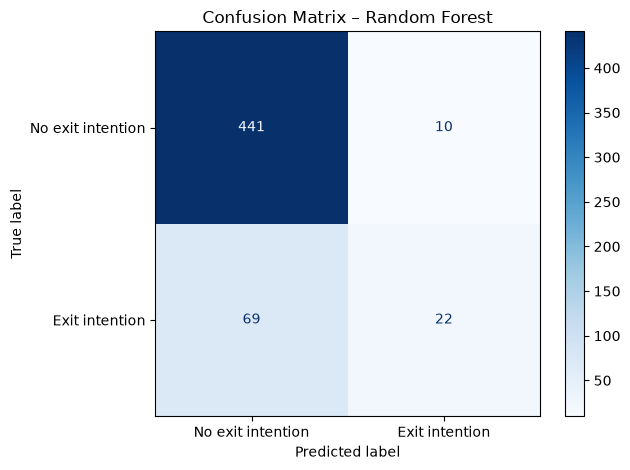

In [222]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Reuse existing training and test sets
X_train_rf = X_train_multi.copy()
X_test_rf = X_test_multi.copy()

# 2. Define predictors
numeric_predictors = [
    "pride",
    "wellbeing",
    "lead_sat",
    "tot_sat"
]


# Ensure appropriate data types
for data in [X_train_rf, X_test_rf]:

    for col in numeric_predictors:
        data[col] = pd.to_numeric(
            data[col], errors="coerce"
        )



# 3. Preprocessing
preprocessor_rf = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"),
     numeric_predictors),
])

# 4. Define Random Forest model
model_rf = Pipeline([
    ("preprocessor", preprocessor_rf),
    ("rf", RandomForestClassifier(
        n_estimators=300,
        criterion="gini",
        max_depth=5,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

# 5. Fit model on training data
model_rf.fit(X_train_rf, y_train)

# 6. Generate predictions
y_pred_train_rf = model_rf.predict(X_train_rf)
y_pred_test_rf = model_rf.predict(X_test_rf)

# Predicted probabilities
y_proba_train_rf = model_rf.predict_proba(
    X_train_rf
)[:, 1]

y_proba_test_rf = model_rf.predict_proba(
    X_test_rf
)[:, 1]

# 7. Training and test scores (accuracy)
train_score_rf = model_rf.score(X_train_rf, y_train)
test_score_rf = model_rf.score(X_test_rf, y_test)

print("RANDOM FOREST CLASSIFIER")
print("------------------------")
print(f"Training score: {train_score_rf:.3f}")
print(f"Test score:     {test_score_rf:.3f}")

# 8. Calculate all performance metrics
results_rf = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Average Precision",
        "Brier Score"
    ],
    "Training": [
        accuracy_score(y_train, y_pred_train_rf),
        precision_score(y_train, y_pred_train_rf, zero_division=0),
        recall_score(y_train, y_pred_train_rf, zero_division=0),
        f1_score(y_train, y_pred_train_rf, zero_division=0),
        roc_auc_score(y_train, y_proba_train_rf),
        average_precision_score(y_train, y_proba_train_rf),
        brier_score_loss(y_train, y_proba_train_rf)
    ],
    "Test": [
        accuracy_score(y_test, y_pred_test_rf),
        precision_score(y_test, y_pred_test_rf, zero_division=0),
        recall_score(y_test, y_pred_test_rf, zero_division=0),
        f1_score(y_test, y_pred_test_rf, zero_division=0),
        roc_auc_score(y_test, y_proba_test_rf),
        average_precision_score(y_test, y_proba_test_rf),
        brier_score_loss(y_test, y_proba_test_rf)
    ]
})

# 9. Generalization gap
results_rf["Gap"] = (
    results_rf["Training"] - results_rf["Test"]
)

print("\nMODEL PERFORMANCE")
display(results_rf.round(3))

# 10. Classification report
print("\nCLASSIFICATION REPORT (TEST DATA)")
print(classification_report(
    y_test,
    y_pred_test_rf,
    zero_division=0
))

# Display results
print("Random Forest Classifier")
print("------------------------")
print(f"Training score: {train_score_rf:.3f}")
print(f"Test score:     {test_score_rf:.3f}")
print(f"MODEL PERFORMANCE")
print("------------------------")
print(f"Training ROC-AUC: {roc_auc_score(y_train, y_proba_train_rf):.3f}")
print(f"Test ROC-AUC:     {roc_auc_score(y_test, y_proba_test_rf):.3f}")
print(f"Training Brier:   {brier_score_loss(y_train, y_proba_train_rf):.3f}")
print(f"Test Brier:       {brier_score_loss(y_test, y_proba_test_rf):.3f}")
print(f"Training Accuracy: {accuracy_score(y_train, y_pred_train_rf):.3f}")
print(f"Test Accuracy:     {accuracy_score(y_test, y_pred_test_rf):.3f}")
print(f"Training F1 Score: {f1_score(y_train, y_pred_train_rf):.3f}")
print(f"Test F1 Score:     {f1_score(y_test, y_pred_test_rf):.3f}")

# 11. Confusion matrix
cm_rf = confusion_matrix(
    y_test, y_pred_test_rf, labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No exit intention", "Exit intention"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix – Random Forest")
plt.tight_layout()
plt.show()

XGBOOST CLASSIFIER
------------------
Training score: 0.863
Test score:     0.862
XGBOOST CLASSIFIER
------------------
Training score: 0.863
Test score:     0.862
MODEL PERFORMANCE
------------------

MODEL PERFORMANCE


,Metric,Training,Test,Gap
0,Accuracy,0.863,0.862,0.001
1,Precision,0.729,0.700,0.029
2,Recall,0.283,0.308,-0.025
3,F1 Score,0.407,0.427,-0.020
4,ROC-AUC,0.801,0.812,-0.011
5,Average Precision,0.546,0.532,0.014
6,Brier Score,0.105,0.107,-0.002



CLASSIFICATION REPORT (TEST DATA)
              precision    recall  f1-score   support

           0       0.87      0.97      0.92       451
           1       0.70      0.31      0.43        91

    accuracy                           0.86       542
   macro avg       0.79      0.64      0.67       542
weighted avg       0.85      0.86      0.84       542



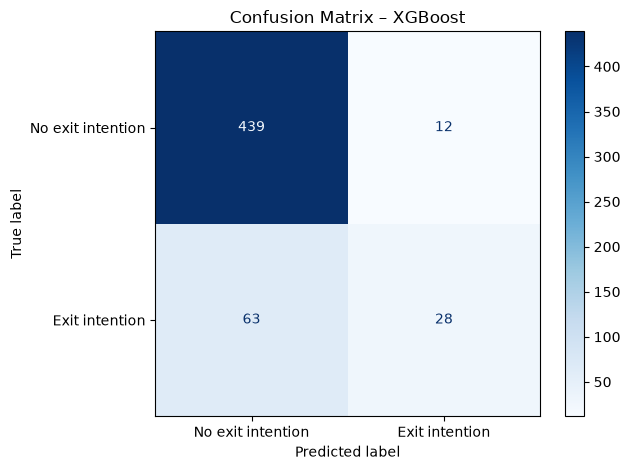

XGBOOST CLASSIFIER
------------------------
Training score: 0.863
Test score:     0.862
MODEL PERFORMANCE
------------------------
Training ROC-AUC: 0.801
Test ROC-AUC:     0.812
Training Brier:   0.105
Test Brier:       0.107
Training Accuracy: 0.863
Test Accuracy:     0.862
Training F1 Score: 0.407
Test F1 Score:     0.427


In [226]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Reuse existing training and test sets
X_train_xgb = X_train_multi.copy()
X_test_xgb = X_test_multi.copy()

# 2. Define predictors
numeric_predictors = [
    "pride",
    "wellbeing",
    "lead_sat",
    "tot_sat"
]


# Ensure appropriate data types
for data in [X_train_xgb, X_test_xgb]:

    for col in numeric_predictors:
        data[col] = pd.to_numeric(
            data[col], errors="coerce"
        )


# 3. Preprocessing
preprocessor_xgb = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"),
     numeric_predictors),
    ])

# 4. Define XGBoost classifier
model_xgb = Pipeline([
    ("preprocessor", preprocessor_xgb),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

# 5. Fit model on training data
model_xgb.fit(X_train_xgb, y_train)

# 6. Predictions
y_pred_train_xgb = model_xgb.predict(X_train_xgb)
y_pred_test_xgb = model_xgb.predict(X_test_xgb)

# Predicted probabilities
y_proba_train_xgb = model_xgb.predict_proba(
    X_train_xgb
)[:, 1]

y_proba_test_xgb = model_xgb.predict_proba(
    X_test_xgb
)[:, 1]

# 7. Training and test scores (accuracy)
train_score_xgb = model_xgb.score(X_train_xgb, y_train)
test_score_xgb = model_xgb.score(X_test_xgb, y_test)

print("XGBOOST CLASSIFIER")
print("------------------")
print(f"Training score: {train_score_xgb:.3f}")
print(f"Test score:     {test_score_xgb:.3f}")

# 8. All performance metrics
results_xgb = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Average Precision",
        "Brier Score"
    ],
    "Training": [
        accuracy_score(y_train, y_pred_train_xgb),
        precision_score(y_train, y_pred_train_xgb, zero_division=0),
        recall_score(y_train, y_pred_train_xgb, zero_division=0),
        f1_score(y_train, y_pred_train_xgb, zero_division=0),
        roc_auc_score(y_train, y_proba_train_xgb),
        average_precision_score(y_train, y_proba_train_xgb),
        brier_score_loss(y_train, y_proba_train_xgb)
    ],
    "Test": [
        accuracy_score(y_test, y_pred_test_xgb),
        precision_score(y_test, y_pred_test_xgb, zero_division=0),
        recall_score(y_test, y_pred_test_xgb, zero_division=0),
        f1_score(y_test, y_pred_test_xgb, zero_division=0),
        roc_auc_score(y_test, y_proba_test_xgb),
        average_precision_score(y_test, y_proba_test_xgb),
        brier_score_loss(y_test, y_proba_test_xgb)
    ]
})

print("XGBOOST CLASSIFIER")
print("------------------")
print(f"Training score: {train_score_xgb:.3f}")
print(f"Test score:     {test_score_xgb:.3f}")
print("MODEL PERFORMANCE")
print("------------------")

# 9. Generalization gap
results_xgb["Gap"] = (
    results_xgb["Training"] - results_xgb["Test"]
)

print("\nMODEL PERFORMANCE")
display(results_xgb.round(3))

# 10. Classification report
print("\nCLASSIFICATION REPORT (TEST DATA)")
print(classification_report(
    y_test,
    y_pred_test_xgb,
    zero_division=0
))

# 11. Confusion matrix
cm_xgb = confusion_matrix(
    y_test, y_pred_test_xgb, labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["No exit intention", "Exit intention"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – XGBoost")
plt.tight_layout()
plt.show()

print("XGBOOST CLASSIFIER")
print("------------------------")
print(f"Training score: {train_score_xgb:.3f}")
print(f"Test score:     {test_score_xgb:.3f}")
print(f"MODEL PERFORMANCE")
print("------------------------")
print(f"Training ROC-AUC: {roc_auc_score(y_train, y_proba_train_xgb):.3f}")
print(f"Test ROC-AUC:     {roc_auc_score(y_test, y_proba_test_xgb):.3f}")
print(f"Training Brier:   {brier_score_loss(y_train, y_proba_train_xgb):.3f}")
print(f"Test Brier:       {brier_score_loss(y_test, y_proba_test_xgb):.3f}")
print(f"Training Accuracy: {accuracy_score(y_train, y_pred_train_xgb):.3f}")
print(f"Test Accuracy:     {accuracy_score(y_test, y_pred_test_xgb):.3f}")
print(f"Training F1 Score: {f1_score(y_train, y_pred_train_xgb):.3f}")
print(f"Test F1 Score:     {f1_score(y_test, y_pred_test_xgb):.3f}")

# Forward Feeding Neural Network with imputation


In [228]:
import torch



In [229]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from pathlib import Path
from tempfile import mkdtemp

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Define predictors (excluding gender)
predictors_nn = [
    "pride",
    "wellbeing",
    "lead_sat",
    "tot_sat"
]

# Reuse existing train/test split
X_train_nn = (
    X_train_multi[predictors_nn]
    .apply(pd.to_numeric, errors="coerce")
    .astype(float)
)

X_test_nn = (
    X_test_multi[predictors_nn]
    .apply(pd.to_numeric, errors="coerce")
    .astype(float)
)

# Create validation subset from training data
X_fit_raw, X_val_raw, y_fit, y_val = train_test_split(
    X_train_nn,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Fit preprocessing on the fitting subset only
preprocess_val = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_fit = preprocess_val.fit_transform(
    X_fit_raw
).astype(np.float32)

X_val = preprocess_val.transform(
    X_val_raw
).astype(np.float32)

In [230]:
class ExitNN(nn.Module):

    def __init__(self, n_features=4):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(n_features, 16),
            nn.ReLU(),

            nn.Linear(16, 8),
            nn.ReLU(),

            nn.Linear(8, 2)
        )

    def forward(self, x):
        return self.layers(x)

In [231]:
def evaluate_exit(model, inputs, targets):

    model.eval()

    with torch.no_grad():
        logits = model(inputs)

        loss = nn.functional.cross_entropy(
            logits, targets
        ).item()

        accuracy = (
            logits.argmax(dim=1) == targets
        ).float().mean().item()

    return loss, accuracy


def train_one_epoch_exit(
    model, loader, loss_function, optimizer
):

    model.train()

    for xb, yb in loader:
        optimizer.zero_grad()

        logits = model(xb)
        loss = loss_function(logits, yb)

        loss.backward()
        optimizer.step()


def train_exit(
    model,
    X_fit,
    y_fit,
    X_val,
    y_val,
    epochs=100,
    learning_rate=0.001,
    batch_size=64,
    patience=15
):

    Path("save").mkdir(exist_ok=True)

    save_dir = Path(
        mkdtemp(prefix="exit_nn_", dir="save")
    )

    # Convert to PyTorch tensors
    X_fit_tensor = torch.tensor(
        X_fit, dtype=torch.float32
    )
    y_fit_tensor = torch.tensor(
        np.asarray(y_fit), dtype=torch.long
    )

    X_val_tensor = torch.tensor(
        X_val, dtype=torch.float32
    )
    y_val_tensor = torch.tensor(
        np.asarray(y_val), dtype=torch.long
    )

    # DataLoader
    loader = DataLoader(
        TensorDataset(X_fit_tensor, y_fit_tensor),
        batch_size=batch_size,
        shuffle=True
    )

    # Loss and optimizer
    loss_function = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.0001
    )

    history = []
    best_loss = np.inf
    best_epoch = 0

    for epoch in range(1, epochs + 1):

        train_one_epoch_exit(
            model, loader, loss_function, optimizer
        )

        train_loss, train_accuracy = evaluate_exit(
            model, X_fit_tensor, y_fit_tensor
        )

        val_loss, val_accuracy = evaluate_exit(
            model, X_val_tensor, y_val_tensor
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_accuracy": train_accuracy,
            "val_accuracy": val_accuracy
        })

        # Save best model
        if val_loss < best_loss - 1e-4:

            best_loss = val_loss
            best_epoch = epoch

            torch.save(
                model.state_dict(),
                save_dir / "best_model.pt"
            )

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"Epoch {epoch:3d}: "
                f"validation loss {val_loss:.3f}, "
                f"accuracy {val_accuracy:.3f}"
            )

        # Early stopping
        if epoch - best_epoch >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    # Restore best model
    model.load_state_dict(
        torch.load(
            save_dir / "best_model.pt",
            map_location="cpu",
            weights_only=True
        )
    )

    return pd.DataFrame(history), save_dir, best_epoch

In [232]:
# Initialize model
model_selection_nn = ExitNN(
    n_features=len(predictors_nn)
)

# Train
history_nn, save_dir_nn, best_epoch_nn = train_exit(
    model_selection_nn,
    X_fit,
    y_fit,
    X_val,
    y_val,
    epochs=100,
    learning_rate=0.001,
    batch_size=64,
    patience=15
)

print(f"\nBest epoch: {best_epoch_nn}")
print(f"Model checkpoint: {save_dir_nn}")

Epoch   1: validation loss 0.684, accuracy 0.501
Epoch  10: validation loss 0.377, accuracy 0.834
Epoch  20: validation loss 0.370, accuracy 0.834
Epoch  30: validation loss 0.366, accuracy 0.834
Epoch  40: validation loss 0.365, accuracy 0.857
Epoch  50: validation loss 0.364, accuracy 0.859
Epoch  60: validation loss 0.363, accuracy 0.859
Epoch  70: validation loss 0.362, accuracy 0.859
Epoch  80: validation loss 0.359, accuracy 0.859
Early stopping at epoch 89

Best epoch: 74
Model checkpoint: c:\Users\guebeli.SPW\GitHub_Repositories\CAS_ADS_2026_Guebco\1_Project_Submissions\M3\save\exit_nn_zrjc0y3_


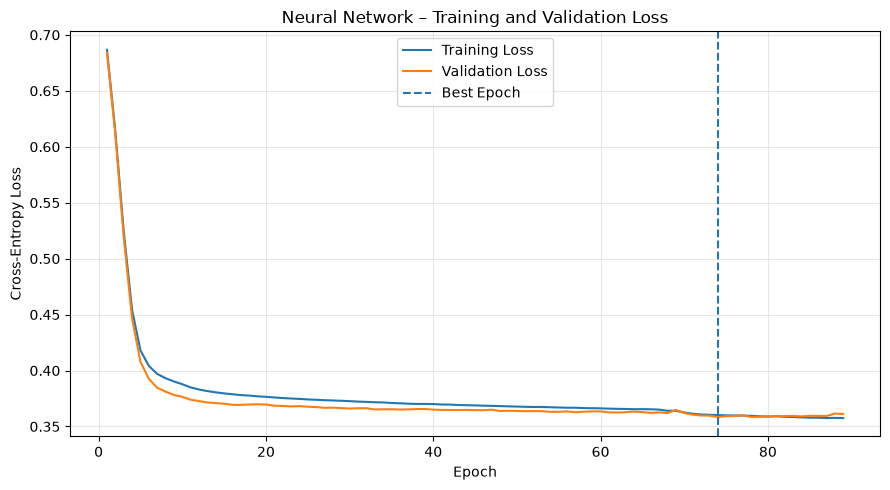

In [233]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_nn["epoch"],
    history_nn["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_nn["epoch"],
    history_nn["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch_nn,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Neural Network – Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [234]:
# Fit preprocessing on full training set
preprocess_nn = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_nn_arr = preprocess_nn.fit_transform(
    X_train_nn
).astype(np.float32)

X_test_nn_arr = preprocess_nn.transform(
    X_test_nn
).astype(np.float32)

# Create training DataLoader
train_tensors = TensorDataset(
    torch.tensor(X_train_nn_arr),
    torch.tensor(y_train.to_numpy(dtype=np.int64))
)

train_loader = DataLoader(
    train_tensors,
    batch_size=64,
    shuffle=True
)

# Initialize fresh model
torch.manual_seed(42)

model_nn = ExitNN(
    n_features=len(predictors_nn)
)

optimizer = torch.optim.Adam(
    model_nn.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

loss_function = nn.CrossEntropyLoss()

# Train for selected number of epochs
for epoch in range(best_epoch_nn):
    train_one_epoch_exit(
        model_nn,
        train_loader,
        loss_function,
        optimizer
    )

print("Final neural network fitted.")

Final neural network fitted.


In [238]:
# Performance metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

def predict_exit_nn(model, X_array):

    model.eval()

    with torch.no_grad():

        logits = model(
            torch.tensor(X_array, dtype=torch.float32)
        )

        probabilities = torch.softmax(
            logits, dim=1
        )[:, 1].numpy()

        predictions = logits.argmax(
            dim=1
        ).numpy()

    return predictions, probabilities


# Training predictions
y_pred_train_nn, y_proba_train_nn = predict_exit_nn(
    model_nn, X_train_nn_arr
)

# Test predictions
y_pred_test_nn, y_proba_test_nn = predict_exit_nn(
    model_nn, X_test_nn_arr
)

# Performance metrics
nn_rows = []

for dataset, y_true, y_pred, y_proba in [
    ("Train", y_train, y_pred_train_nn, y_proba_train_nn),
    ("Test", y_test, y_pred_test_nn, y_proba_test_nn)
]:

    nn_rows.append({
        "Model": "Neural Network",
        "Dataset": dataset,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "Average Precision": average_precision_score(
            y_true, y_proba
        ),
        "Brier": brier_score_loss(y_true, y_proba)
    })

results_nn = pd.DataFrame(nn_rows)

print("NEURAL NETWORK — MODEL PERFORMANCE")
display(results_nn.round(3))

# Accuracy generalization gap
train_acc = results_nn.loc[
    results_nn["Dataset"] == "Train", "Accuracy"
].iloc[0]

test_acc = results_nn.loc[
    results_nn["Dataset"] == "Test", "Accuracy"
].iloc[0]

print(f"\nTraining score: {train_acc:.3f}")
print(f"Test score:     {test_acc:.3f}")
print(f"Accuracy gap:   {train_acc - test_acc:.3f}")

print("NEURAL NETWORK CLASSIFIER")
print("------------------------")
print(f"Training score: {accuracy_score(y_train, y_pred_train_nn):.3f}")
print(f"Test score:     {accuracy_score(y_test, y_pred_test_nn):.3f}")

print("\nMODEL PERFORMANCE")
print("------------------------")
print(f"Training ROC-AUC: {roc_auc_score(y_train, y_proba_train_nn):.3f}")
print(f"Test ROC-AUC:     {roc_auc_score(y_test, y_proba_test_nn):.3f}")

print(f"Training Brier:   {brier_score_loss(y_train, y_proba_train_nn):.3f}")
print(f"Test Brier:       {brier_score_loss(y_test, y_proba_test_nn):.3f}")

print(f"Training Accuracy: {accuracy_score(y_train, y_pred_train_nn):.3f}")
print(f"Test Accuracy:     {accuracy_score(y_test, y_pred_test_nn):.3f}")

print(f"Training F1 Score: {f1_score(y_train, y_pred_train_nn, zero_division=0):.3f}")
print(f"Test F1 Score:     {f1_score(y_test, y_pred_test_nn, zero_division=0):.3f}")

NEURAL NETWORK — MODEL PERFORMANCE


,Model,Dataset,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier
0,Neural Network,Train,0.857,0.660,0.296,0.409,0.793,0.485,0.109
1,Neural Network,Test,0.862,0.682,0.330,0.444,0.808,0.497,0.108



Training score: 0.857
Test score:     0.862
Accuracy gap:   -0.004
NEURAL NETWORK CLASSIFIER
------------------------
Training score: 0.857
Test score:     0.862

MODEL PERFORMANCE
------------------------
Training ROC-AUC: 0.793
Test ROC-AUC:     0.808
Training Brier:   0.109
Test Brier:       0.108
Training Accuracy: 0.857
Test Accuracy:     0.862
Training F1 Score: 0.409
Test F1 Score:     0.444


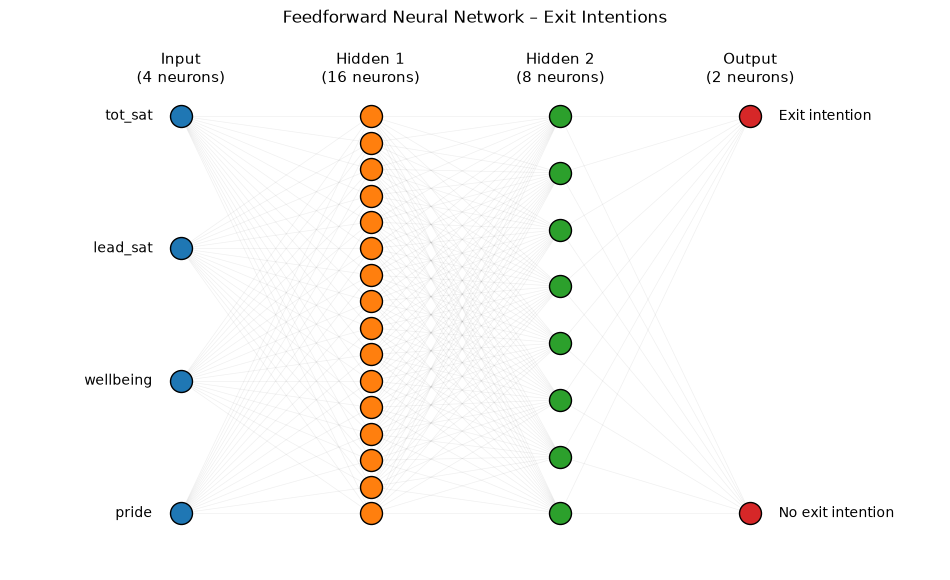

In [236]:
# Neural network architecture
layers = [4, 16, 8, 2]
labels = ["Input", "Hidden 1", "Hidden 2", "Output"]

fig, ax = plt.subplots(figsize=(12, 7))

for i, n in enumerate(layers):
    y = np.linspace(-7, 7, n)

    # Draw connections
    if i > 0:
        y_prev = np.linspace(-7, 7, layers[i-1])
        for a in y_prev:
            for b in y:
                ax.plot([i-1, i], [a, b],
                        color="gray", alpha=0.12, linewidth=0.5)

    # Draw neurons
    ax.scatter([i]*n, y, s=250, edgecolors="black", zorder=3)
    ax.text(i, 8.2, f"{labels[i]}\n({n} neurons)",
            ha="center", fontsize=11)

# Predictor and outcome labels
for y, name in zip(np.linspace(-7, 7, 4),
                   ["pride", "wellbeing", "lead_sat", "tot_sat"]):
    ax.text(-0.15, y, name, ha="right", va="center")

ax.text(3.15, -7, "No exit intention", va="center")
ax.text(3.15, 7, "Exit intention", va="center")

ax.set_xlim(-0.9, 4)
ax.set_ylim(-9, 10)
ax.axis("off")
plt.title("Feedforward Neural Network – Exit Intentions")
plt.show()

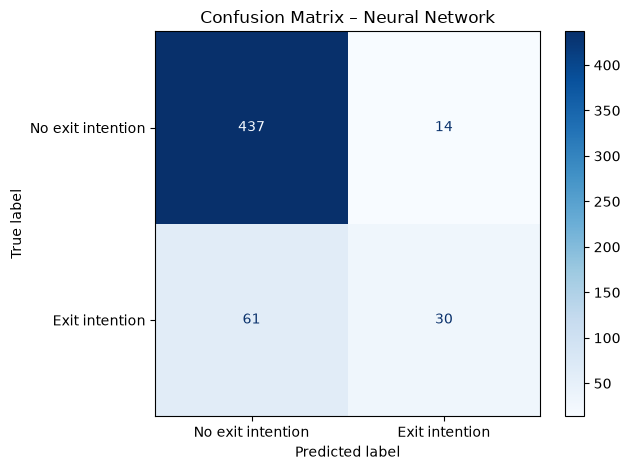


CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.88      0.97      0.92       451
           1       0.68      0.33      0.44        91

    accuracy                           0.86       542
   macro avg       0.78      0.65      0.68       542
weighted avg       0.84      0.86      0.84       542



In [237]:
#confusion matrix
cm_nn = confusion_matrix(
    y_test,
    y_pred_test_nn,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nn,
    display_labels=["No exit intention", "Exit intention"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix – Neural Network")
plt.tight_layout()
plt.show()

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_pred_test_nn,
        zero_division=0
    )
)

In [240]:
# Add Neural Network to existing model comparison
comparison_df = pd.concat([
    comparison_df[
        comparison_df["Model"] != "Neural Network"
    ],
    results_nn
], ignore_index=True)

# Rank models by Test F1 Score (descending)
f1_ranking = (
    comparison_df[comparison_df["Dataset"] == "Test"]
    .sort_values("F1", ascending=False)["Model"]
    .tolist()
)

# Apply ranking to both training and test rows
comparison_df["Model"] = pd.Categorical(
    comparison_df["Model"],
    categories=f1_ranking,
    ordered=True
)

comparison_df = comparison_df.sort_values(
    by=["Model", "Dataset"],
    ascending=[True, False]
).reset_index(drop=True)

# Display results
print("MODEL COMPARISON — RANKED BY TEST F1 SCORE")
display(comparison_df.round(3))

MODEL COMPARISON — RANKED BY TEST F1 SCORE


,Model,Dataset,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier
0,Neural Network,Train,0.857,0.660,0.296,0.409,0.793,0.485,0.109
1,Neural Network,Test,0.862,0.682,0.330,0.444,0.808,0.497,0.108
2,Logistic Regression,Train,0.854,0.672,0.238,0.352,0.776,0.498,0.111
3,Logistic Regression,Test,0.860,0.714,0.275,0.397,0.790,0.521,0.110
4,XGBoost,Train,0.865,0.754,0.280,0.408,0.806,0.563,0.103
5,XGBoost,Test,0.854,0.667,0.264,0.378,0.799,0.525,0.109
6,Linear SVC,Train,0.854,0.683,0.227,0.341,0.776,0.497,0.111
7,Linear SVC,Test,0.856,0.697,0.253,0.371,0.790,0.521,0.110
8,Decision Tree,Train,0.857,0.758,0.208,0.326,0.764,0.460,0.110
9,Decision Tree,Test,0.854,0.714,0.220,0.336,0.761,0.449,0.111


# Comparison

Now I'm comparing the different models.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# 1. Define models
models_to_compare = {
    "Logistic Regression": model_logit_multi,
    "Decision Tree": model_tree,
    "Random Forest": model_rf,
    "XGBoost": model_xgb,
    "Linear SVC": model_svc,
}

# 2. Use identical training and test observations
X_tr = X_train_multi
X_te = X_test_multi

assert X_tr.index.equals(y_train.index)
assert X_te.index.equals(y_test.index)

# 3. Calculate performance metrics
comparison_results = []

for name, model in models_to_compare.items():

    for dataset, X_data, y_data in [
        ("Train", X_tr, y_train),
        ("Test", X_te, y_test)
    ]:

        # Predictions
        y_pred = model.predict(X_data)
        y_proba = model.predict_proba(X_data)[:, 1]

        # Calculate metrics
        comparison_results.append({
            "Model": name,
            "Dataset": dataset,
            "Accuracy": accuracy_score(y_data, y_pred),
            "Precision": precision_score(
                y_data, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_data, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_data, y_pred, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_data, y_proba),
            "Average Precision": average_precision_score(
                y_data, y_proba
            ),
            "Brier": brier_score_loss(y_data, y_proba)
        })

# 4. Create comparison table
comparison_df = pd.DataFrame(comparison_results)

print("MODEL COMPARISON — TRAINING AND TEST PERFORMANCE")
display(comparison_df.round(3))

# 5. Calculate generalization gap (accuracy)
accuracy_comparison = comparison_df.pivot(
    index="Model",
    columns="Dataset",
    values="Accuracy"
)

accuracy_comparison["Gap"] = (
    accuracy_comparison["Train"] -
    accuracy_comparison["Test"]
)

print("\nTRAINING VS TEST ACCURACY")
display(accuracy_comparison.round(3))

MODEL COMPARISON — TRAINING AND TEST PERFORMANCE


,Model,Dataset,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier
0,Logistic Regression,Train,0.854,0.672,0.238,0.352,0.776,0.498,0.111
1,Logistic Regression,Test,0.860,0.714,0.275,0.397,0.790,0.521,0.110
2,Decision Tree,Train,0.857,0.758,0.208,0.326,0.764,0.460,0.110
3,Decision Tree,Test,0.854,0.714,0.220,0.336,0.761,0.449,0.111
4,Random Forest,Train,0.856,0.775,0.191,0.307,0.795,0.524,0.108
5,Random Forest,Test,0.852,0.720,0.198,0.310,0.798,0.531,0.109
6,XGBoost,Train,0.865,0.754,0.280,0.408,0.806,0.563,0.103
7,XGBoost,Test,0.854,0.667,0.264,0.378,0.799,0.525,0.109
8,Linear SVC,Train,0.854,0.683,0.227,0.341,0.776,0.497,0.111
9,Linear SVC,Test,0.856,0.697,0.253,0.371,0.790,0.521,0.110



TRAINING VS TEST ACCURACY


Dataset,Test,Train,Gap
Model,,,
Decision Tree,0.854,0.857,0.003
Linear SVC,0.856,0.854,-0.003
Logistic Regression,0.860,0.854,-0.006
Random Forest,0.852,0.856,0.003
XGBoost,0.854,0.865,0.010


In [ ]:
df.describe()

,id,exit_binary,tot_sat,pride,wellbeing,lead_sat,gender
count,6612.000000,2743.000000,5374.000000,2510.000000,2539.000000,3463.000000,2417.000000
mean,3311.500000,0.168064,3.984369,4.406773,4.484049,4.110887,0.713281
std,1908.864322,0.373991,1.157010,0.825965,0.764176,0.967618,0.456875
min,6.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,1658.750000,0.000000,4.000000,4.000000,4.000000,4.000000,0.000000
50%,3311.500000,0.000000,4.000000,5.000000,5.000000,4.000000,1.000000
75%,4964.250000,0.000000,5.000000,5.000000,5.000000,5.000000,1.000000
max,6617.000000,1.000000,5.000000,5.000000,5.000000,5.000000,2.000000


# UMAP

In [ ]:
import umap

umap_model = umap.UMAP(n_neighbors=50, n_components=2, random_state=1711, n_jobs=1)

umap_df=df[numeric_predictors + ["exit_binary"]].dropna()

umap_nlp = umap_model.fit_transform(umap_df[numeric_predictors])

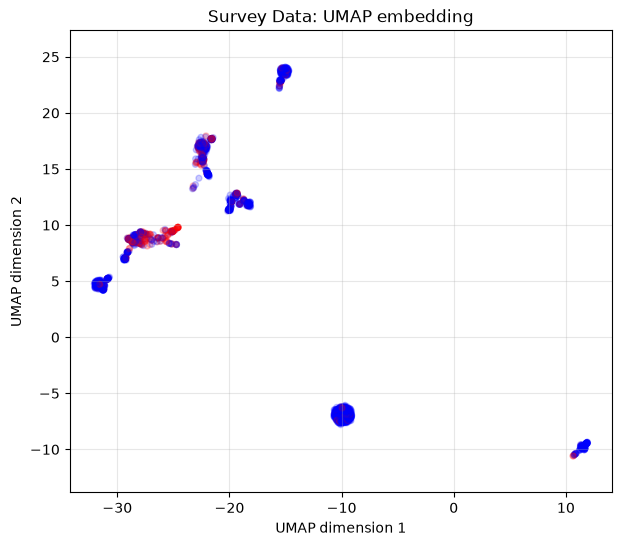

In [ ]:

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(umap_nlp[:, 0], umap_nlp[:, 1], s=18, alpha=0.2, c=umap_df["exit_binary"].map({0: "blue", 1: "red", np.nan: "gray"}), label=umap_df["exit_binary"].map({0: "No exit intention", 1: "Exit intention"}))

ax.set(
    title="Survey Data: UMAP embedding",
    xlabel="UMAP dimension 1",
    ylabel="UMAP dimension 2",
)
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

plt.show()